# Baseline and Detection Quality

This notebook answers two questions:
1. Does active adaptation (drift detector + model reset) help compared to the same tree without any drift detection?
2. How well do the detectors find the true drifts (delay, missed drifts, extra detections)?

In [1]:
%load_ext autoreload
%autoreload 2

import sys
import os
import matplotlib.pyplot as plt

# Add src folder to path
sys.path.append(os.path.abspath('../src'))
from evaluation import evaluate_stream, print_accuracy_table, print_quality_table, STREAMS, DETECTORS
from plotting import plot_baseline_vs_ddm

plt.rcParams.update({'font.size': 12, 'figure.figsize': (12, 6)})

## Baseline vs Active Adaptation

I compare the Hoeffding Tree without any drift detection (baseline) with the same tree that is reset by DDM. This shows if the adaptation helps at all.

Stream   Method        Accuracy  Macro-F1  Resets
Abrupt   No detector     67.24%    67.24%       0
Abrupt   DDM             72.59%    72.59%       6
Gradual  No detector     66.64%    66.64%       0
Gradual  DDM             72.20%    72.19%       9


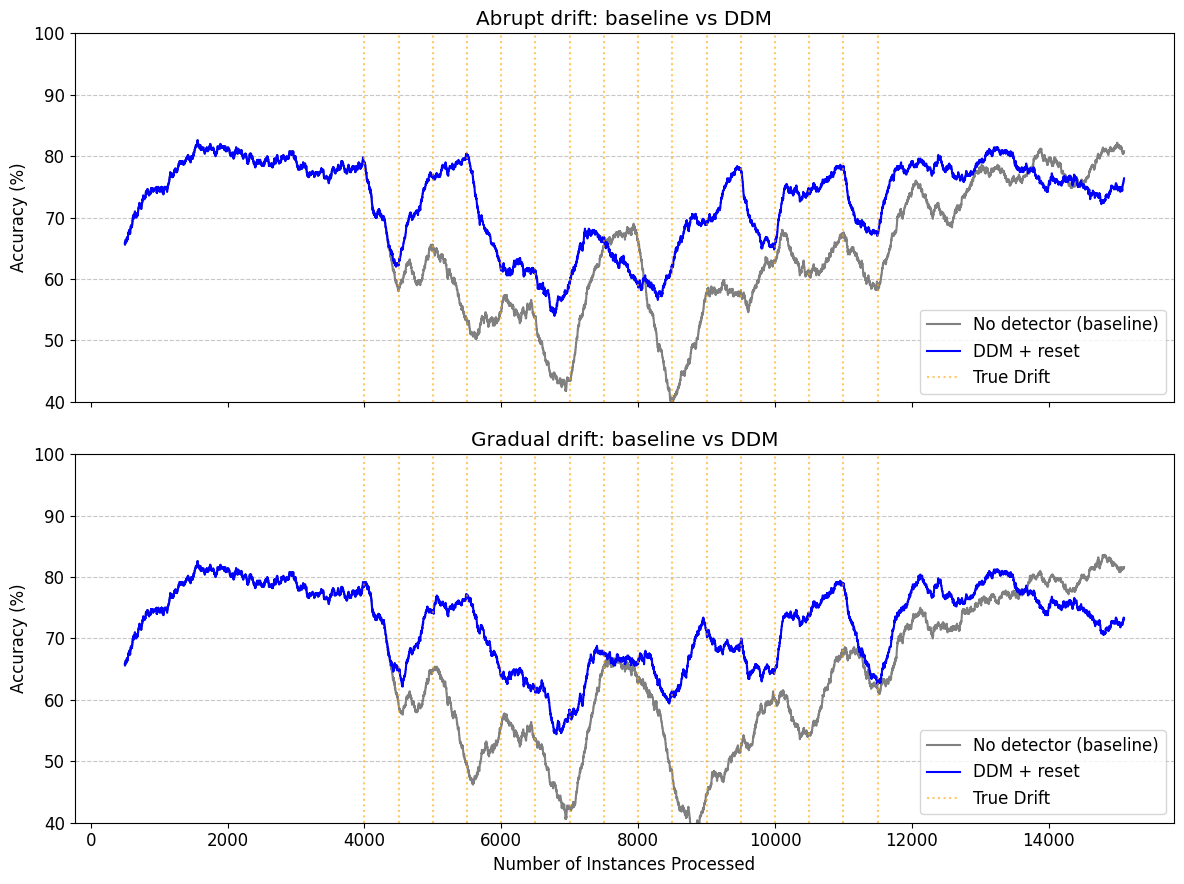

In [2]:
results = {}
for stream_name, path in STREAMS.items():
    results[stream_name] = {
        'No detector': evaluate_stream(path),
        'DDM': evaluate_stream(path, DETECTORS['DDM']()),
    }

print_accuracy_table(results)
plot_baseline_vs_ddm(results, '../images/baseline_vs_ddm.png')

### Results: Baseline vs DDM

| Stream | Method | Accuracy | Macro-F1 | Resets |
|--------|--------|----------|----------|--------|
| Abrupt | No detector | 67.24% | 67.24% | 0 |
| Abrupt | DDM | 72.59% | 72.59% | 6 |
| Gradual | No detector | 66.64% | 66.64% | 0 |
| Gradual | DDM | 72.20% | 72.19% | 9 |

- DDM with reset is about 5 points better than the tree without a detector on both streams (+5.35 on abrupt, +5.56 on gradual).
- The baseline accuracy starts to fall right after the first true drift (4000) and goes down to about 40% in the middle of the stream. With DDM the lowest point is about 55%.
- Both curves are the same until the first reset (about 4350), because DDM did not detect anything before that.
- Near the end of the stream (after about 14000 instances) the baseline is better: about 80-82% against 73-76% for DDM. A possible reason is that the baseline keeps everything it learned, while the reset tree has to learn again. I did not test this.

## Detection Quality: Delay and Missed Drifts

The true drift positions are known (orange lines), so I can measure how good each detector is. A true drift at position `t` counts as found if the detector fires in the window `[t, t + 500)`. The delay is the number of instances between the true drift and the first detection in this window. Extra detections inside a window are counted as repeated, and detections outside all windows are counted as outside. Because the true drifts are only 500 instances apart, the matching is approximate.

In [3]:
for stream_name, path in STREAMS.items():
    for name in ['ADWIN', 'EDDM', 'Page-Hinkley']:
        results[stream_name][name] = evaluate_stream(path, DETECTORS[name]())

print_quality_table(results)

Stream   Detector       Accuracy  Macro-F1  Resets   Found  Mean delay  Repeated  Outside
Abrupt   DDM              72.59%    72.59%       6    6/16         172         0        0
Abrupt   ADWIN            71.68%    71.63%       7    6/16         164         0        1
Abrupt   EDDM             71.03%    71.02%      24    9/16         172        12        3
Abrupt   Page-Hinkley     69.86%    69.86%       9    5/16         295         0        4
Gradual  DDM              72.20%    72.19%       9    8/16         212         1        0
Gradual  ADWIN            69.91%    69.84%       7    6/16         224         0        1
Gradual  EDDM             72.18%    72.14%      42   15/16         102        23        4
Gradual  Page-Hinkley     69.57%    69.55%       8    5/16         255         0        3

Missed true drifts for DDM (Abrupt): [4500, 5000, 6000, 7000, 7500, 8500, 9000, 10000, 10500, 11500]

Missed true drifts for DDM (Gradual): [4500, 5000, 6000, 8500, 9000, 10000, 10500, 1150

### Results: Detection Quality

| Stream | Detector | Resets | Found | Mean delay | Repeated | Outside |
|--------|----------|--------|-------|------------|----------|---------|
| Abrupt | DDM | 6 | 6/16 | 172 | 0 | 0 |
| Abrupt | ADWIN | 7 | 6/16 | 164 | 0 | 1 |
| Abrupt | EDDM | 24 | 9/16 | 172 | 12 | 3 |
| Abrupt | Page-Hinkley | 9 | 5/16 | 295 | 0 | 4 |
| Gradual | DDM | 9 | 8/16 | 212 | 1 | 0 |
| Gradual | ADWIN | 7 | 6/16 | 224 | 0 | 1 |
| Gradual | EDDM | 42 | 15/16 | 102 | 23 | 4 |
| Gradual | Page-Hinkley | 8 | 5/16 | 255 | 0 | 3 |

- DDM and ADWIN make almost no extra detections (0-1), but they find only 6-8 of the 16 true drifts. On the abrupt stream DDM found only the drifts at 4000, 5500, 6500, 8000, 9500 and 11000.
- On the gradual stream 8 of the 9 DDM detections match a true drift and only 1 is repeated, so the cluster of detections between 6800 and 8250 is mostly real changes.
- EDDM finds the most true drifts (9/16 and 15/16) and has the smallest delay on gradual (102), but most of its resets are extra (12 + 3 on abrupt, 23 + 4 on gradual).
- Page-Hinkley is the slowest (delay 295 and 255) and finds the fewest drifts (5/16).
- The delay is calculated only for found drifts, and the largest possible value is 499 because of the 500 window.
- The true drifts are 500 instances apart, so the windows cover the whole range from 4000 to 12000. Because of this, EDDM may find some drifts only because it fires very often, and its "Found" value should be read with care.

## Final Conclusion

- Active adaptation helps: DDM with reset is about 5 points better than the tree without a detector on both streams.
- The adaptation is not perfect. The reset removes what the tree learned before, and near the end of the stream the baseline is better than DDM.
- DDM has the best accuracy with only 6-9 resets and almost no extra detections, but it finds only about half of the true drifts (6/16 and 8/16).
- EDDM finds the most true drifts (up to 15/16), but it resets the model very often. On the gradual stream its accuracy is the same as DDM (72.18% vs 72.20%), and on the abrupt stream it is lower (71.03% vs 72.59%).
- ADWIN and Page-Hinkley are worse than DDM in accuracy on both streams, and Page-Hinkley also has the largest delay.